# **Regresión Ridge/Lasso**
#### "Nadie es inútil, pero nadie es tan importante"


## 0. Marco teorico

- La **regularización** obliga a un modelo a ser más "humilde", sacrificando un poco de precisión sobre los datos que ya conoce a cambio de acertar más sobre los que todavía no ha visto.

- Añade un "castigo" al tamaño de los coeficientes dentro de la fórmula que el modelo minimiza.

- Sirve para evitar el **sobreajuste**, controlar la **multicolinealidad** (variables que dicen casi lo mismo y vuelven los coeficientes inestables).


**Cuándo lo usamos en la práctica:**
- Cuando hay **muchas variables frente a pocos datos*, están **muy correlacionadas entre sí**, y cuando el bjetivo es **predecir**, no solo describir lo ya ocurrido.

### 0.1 El problema de fondo: sobreajuste

Un modelo tiene dos formas de equivocarse:

- **Sesgo (bias):** es demasiado simple y no captura el patrón real. Se equivoca siempre igual.
- **Varianza:** es tan flexible que persigue el ruido de los datos concretos con los que se entrenó. Cambia de opinión con cualquier dato nuevo.


### 0.2 Ridge y Lasso: dos hermanos que ponen disciplina

> *"Nadie es inútil, pero nadie es tan importante"*

MCO es el padre permisivo: deja que **cada variable pida el peso que quiera** con tal de ajustar los datos. Cuando hay variables redundantes, eso produce coeficientes enormes que se cancelan entre sí.

Ridge y Lasso son los dos hermanos que cobran un **impuesto sobre el tamaño de los coeficientes**. La diferencia está en **cómo cobran**:

| | **Ridge** (L2) | **Lasso** (L1) |
|---|---|---|
| Castiga | el **cuadrado** del coeficiente | el **valor absoluto** |
| A quién aprieta | duro a los grandes, casi nada a los pequeños | **igual a todos**, sin importar su tamaño |
| Resultado | todos encogen, **ninguno llega a cero** | los que no aportan **caen exactamente a cero** |
| Su lema | *"nadie es inútil"* | *"nadie es tan importante"* |



### 0.3  El parámetro $\alpha$ (alfa) - la perilla del castigo:

- $\alpha = 0$: no hay castigo, es MCO puro.
- $\alpha$ pequeño: castigo leve, el modelo se parece a MCO.
- $\alpha$ grande: castigo fuerte, los coeficientes se aplastan hacia cero.
- $\alpha \to \infty$: todos los coeficientes valen cero, el modelo predice siempre el promedio.


In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import GridSearchCV
import statsmodels.api as sm

pio.templates.default = "plotly_dark"
plt.style.use('dark_background')

import warnings
warnings.filterwarnings('ignore')

## 1. Carga y preparación de datos

### 1.1 Fuente y contexto del dataset

- Datos del **repositorio de la Organización Mundial de la Salud (OMS)**, complementados con datos económicos de la ONU.
- Reúnen indicadores de **salud, economía y educación** de países de todo el mundo.
- Pregunta que motiva el análisis: *¿qué factores explican que en un país se viva más años?*

**Granularidad: una fila = un país en un año**

- **193 países**, período **2000–2015** (16 años).
- 2938 filas en total. No es un panel perfecto: algunos países no tienen los 16 años completos.
- Esto importa: las filas **no son independientes entre sí**. Colombia-2014 y Colombia-2015 se parecen mucho.

**Variable objetivo ($y$)**

- \`Life expectancy \` — **esperanza de vida al nacer, en años**.
- Es una variable **numérica continua**, por eso el problema es de **regresión** y no de clasificación.
- Rango aproximado: de 36 a 89 años.

**Variables explicativas ($X$)**

- 21 columnas restantes, agrupables en cuatro familias:
  - **Mortalidad:** \`Adult Mortality\`, \`infant deaths\`, \`under-five deaths\`.
  - **Enfermedad e inmunización:** \`Hepatitis B\`, \`Measles \`, \`Polio\`, \`Diphtheria \`, \` HIV/AIDS\`.
  - **Economía:** \`GDP\`, \`percentage expenditure\`, \`Total expenditure\`, \`Income composition of resources\`.
  - **Social y nutrición:** \`Schooling\`, \`Alcohol\`, \` BMI \`, \`Population\`, indicadores de delgadez.

>!!!! estas variables **no son independientes entre sí**. Las muertes infantiles y las de menores de cinco años miden casi lo mismo; el PIB y el gasto en salud se mueven juntos; escolaridad e ingreso también. Esa **alta correlación entre variables explicativas** es exactamente el escenario donde MCO falla y donde Ridge y Lasso tienen algo que aportar.

In [ ]:
# Subimos el dataset

import os
import urllib.request

ARCHIVO = 'Life Expectancy Data.csv'
URL = ('https://raw.githubusercontent.com/EvidenceN/DataSets/'
       'master/Life%20Expectancy%20Data.csv')

def _dataset_valido(ruta):
    """El resto del notebook depende de los nombres de columna ORIGINALES del
    dataset WHO, que traen espacios significativos (' BMI ', 'Life expectancy ',
    ' thinness  1-19 years' con dos espacios). Si faltan, el archivo no sirve."""
    if not os.path.exists(ruta):
        return False
    cols = pd.read_csv(ruta, nrows=0).columns
    return all(c in cols for c in ['Life expectancy ', ' BMI ', ' thinness  1-19 years'])

if not _dataset_valido(ARCHIVO):
    print('Dataset ausente o con columnas alteradas. Descargando el original...')
    urllib.request.urlretrieve(URL, ARCHIVO)

_chk = pd.read_csv(ARCHIVO)
print('Dataset listo:', _chk.shape[0], 'filas y', _chk.shape[1], 'columnas')

Dataset ausente o con columnas alteradas. Descargando el original...
Dataset listo: 2938 filas y 22 columnas


In [ ]:
data = pd.read_csv('Life Expectancy Data.csv')
print(data.shape)
data.head()

(2938, 22)


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [ ]:
# --- Radiografia del dataset ------------------------------------------------
# 1) Granularidad: comprobamos que cada fila es un par (pais, anio) unico.
print('Filas totales      :', len(data))
print('Paises distintos   :', data['Country'].nunique())
print('Periodo cubierto   :', data['Year'].min(), '-', data['Year'].max())
print('Duplicados pais-anio:', data.duplicated(subset=['Country', 'Year']).sum())
print()

# 2) Inventario de variables: naturaleza, faltantes y cardinalidad.
#    'object' = texto  ->  categorica ; el resto -> numerica
inventario = pd.DataFrame({
    'Tipo'           : data.dtypes.astype(str),
    'Naturaleza'     : np.where(data.dtypes == 'object', 'CATEGORICA', 'numerica'),
    'Valores unicos' : data.nunique(),
    'Nulos'          : data.isnull().sum(),
    '% Nulos'        : (data.isnull().sum() / len(data) * 100).round(1)
})

print('Variables categoricas:', (inventario['Naturaleza'] == 'CATEGORICA').sum())
print('Variables numericas  :', (inventario['Naturaleza'] == 'numerica').sum())
print('Columnas con datos faltantes:', (inventario['Nulos'] > 0).sum(), 'de', len(inventario))

inventario.sort_values('% Nulos', ascending=False)

Filas totales      : 2938
Paises distintos   : 193
Periodo cubierto   : 2000 - 2015
Duplicados pais-anio: 0

Variables categoricas: 2
Variables numericas  : 20
Columnas con datos faltantes: 14 de 22


,Tipo,Naturaleza,Valores unicos,Nulos,% Nulos
Population,float64,numerica,2278,652,22.2
Hepatitis B,float64,numerica,87,553,18.8
GDP,float64,numerica,2490,448,15.2
Total expenditure,float64,numerica,818,226,7.7
Alcohol,float64,numerica,1076,194,6.6
Income composition of resources,float64,numerica,625,167,5.7
Schooling,float64,numerica,173,163,5.5
thinness 1-19 years,float64,numerica,200,34,1.2
thinness 5-9 years,float64,numerica,207,34,1.2
BMI,float64,numerica,608,34,1.2


### 1.2 Tratamiento de las variables categóricas

| Variable | Cardinalidad | Decisión | Por qué |
|---|---|---|---|
| \`Status\` | 2 (*Developed* / *Developing*) | **Codificación binaria** → 1 / 0 | Con solo dos categorías, una columna basta. Queda lista para entrar al modelo. |
| \`Country\` | 193 | **Se descarta** | Codificarla daría 193 columnas nuevas para 2938 filas. El modelo memorizaría cada país en vez de aprender el patrón general. |

También decidimos descrtar \`**Year**\`: aunque es numérica, aquí funciona como etiqueta temporal y no como un factor causal de la esperanza de vida.

**Sobre la codificación binaria de \`Status\`:**

- Al tener solo dos niveles, no hace falta *one-hot encoding*: una variable binaria ya representa toda la información.
- Interpretación directa del coeficiente: **cuántos años de esperanza de vida se asocian a ser un país desarrollado**, manteniendo lo demás constante.


### 1.3 Imputación de valores faltantes

Casi todas las variables tienen huecos. Eliminar las filas incompletas costaría cerca de la mitad del dataset,por lo que debemos **imputar**.


- **Pocos faltantes** (\`Life expectancy \`, \`Adult Mortality\`): se rellenan con la **media** de la columna. no distorsionan la distribución por ser pocos registros.
- **Muchos faltantes** (el resto): se imputa **por rangos de una variable de referencia**.

1. Se elige una variable de referencia que esté **correlacionada** con la que tiene huecos y que esté (casi) completa.
2. Se parte esa referencia en tramos (por ejemplo, escolaridad de 0-2.5, 2.5-5, 5-7.5 años...).
3. A cada hueco se le asigna el valor típico de su tramo.
4. Pero esto solo funcionaria si estan correlacionadas de verdad.





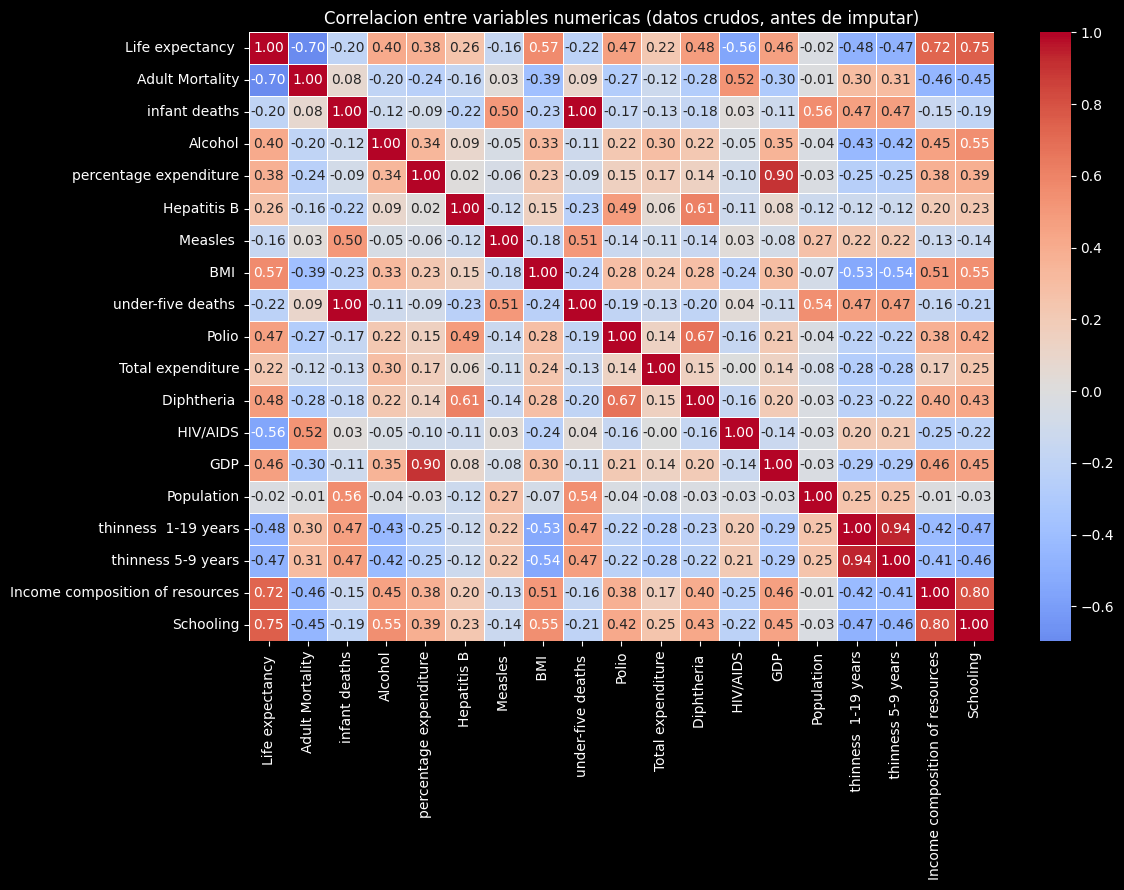

In [ ]:
num = data.select_dtypes(include=[np.number]).drop(columns=['Year'], errors='ignore')

plt.figure(figsize=(12, 9))
sns.heatmap(num.corr(), cmap='coolwarm', center=0, linewidths=.5, annot=True, fmt=".2f")
plt.title('Correlacion entre variables numericas (datos crudos, antes de imputar)')
plt.tight_layout()
plt.show()

In [ ]:

# --- Justificacion par por par ----------------------------------------------
# Cada fila responde: "¿tengo derecho a imputar A usando B?"

pares = [
    ('Alcohol',                         'Schooling'),
    ('Polio',                           'Life expectancy '),
    ('Diphtheria ',                     'Polio'),
    ('Hepatitis B',                     'Diphtheria '),
    (' BMI ',                           'Life expectancy '),
    ('Total expenditure',               'Alcohol'),
    ('GDP',                             'percentage expenditure'),
    ('Population',                      'infant deaths'),
    (' thinness  1-19 years',           ' BMI '),
    (' thinness 5-9 years',             ' BMI '),
    ('Income composition of resources', 'Life expectancy '),
    ('Schooling',                       'Life expectancy '),
]

justificacion = pd.DataFrame([{
    'Variable a imputar'    : c,
    '% faltante'            : round(data[c].isnull().mean() * 100, 1),
    'Variable de referencia': r,
    'Correlacion'           : round(data[c].corr(data[r]), 3)
} for c, r in pares])

# Etiqueta de lectura rapida para la presentacion.
justificacion['Fuerza'] = pd.cut(justificacion['Correlacion'].abs(),
                                 bins=[-0.01, 0.30, 0.50, 1.00],
                                 labels=['debil', 'moderada', 'fuerte'])

justificacion = justificacion.reindex(
    justificacion['Correlacion'].abs().sort_values(ascending=False).index
).reset_index(drop=True)

print('Pares con correlacion fuerte (|r| > 0.5):', (justificacion['Fuerza'] == 'fuerte').sum(), 'de', len(pares))
justificacion

Pares con correlacion fuerte (|r| > 0.5): 10 de 12


,Variable a imputar,% faltante,Variable de referencia,Correlacion,Fuerza
0,GDP,15.2,percentage expenditure,0.899,fuerte
1,Schooling,5.5,Life expectancy,0.752,fuerte
2,Income composition of resources,5.7,Life expectancy,0.725,fuerte
3,Diphtheria,0.6,Polio,0.674,fuerte
4,Hepatitis B,18.8,Diphtheria,0.611,fuerte
5,BMI,1.2,Life expectancy,0.568,fuerte
6,Population,22.2,infant deaths,0.557,fuerte
7,Alcohol,6.6,Schooling,0.547,fuerte
8,thinness 5-9 years,1.2,BMI,-0.539,fuerte
9,thinness 1-19 years,1.2,BMI,-0.532,fuerte


In [ ]:
# Ejemplo de UNA de las reglas de imputacion: Alcohol se rellena segun
# Schooling. La nube muestra que a mayor escolaridad, mayor consumo registrado,
# que es lo que da derecho a usar Schooling como referencia.
px.scatter(data.dropna(subset=['Schooling', 'Alcohol']), x='Schooling', y='Alcohol', color='Country',
           title='<b>Schooling vs Alcohol (relación usada para imputar)')

In [ ]:
# --- Imputacion del resto de variables ---------


data['Life expectancy '] = data['Life expectancy '].fillna(data['Life expectancy '].mean())
data['Adult Mortality'] = data['Adult Mortality'].fillna(data['Adult Mortality'].mean())

# Codificacion de la unica categorica que se conserva (seccion 1.2):
#   'Developed' -> 1   |   'Developing' -> 0
# Con solo dos niveles, una columna binaria basta: no hace falta one-hot.
data['Status'] = data['Status'].apply(lambda x: 1 if x == 'Developed' else 0)

def impute_by_ranges(col, ref_col, bins, values):
    """Rellena los nulos de 'col' segun en que tramo de 'ref_col' cae cada fila.

    col    : variable con huecos que queremos completar.
    ref_col: variable de referencia, correlacionada con ella y (casi) completa.
    bins   : cortes que definen los tramos de la referencia.
    values : valor a imputar en cada tramo (un valor por tramo).

    Ejemplo: si un pais tiene 3 anios de escolaridad y no reporta consumo de
    alcohol, se le asigna el consumo tipico de los paises de ese tramo, en vez
    del promedio mundial, que no se le parece.
    """
    ref = data[ref_col]
    mask = data[col].isnull()                 # solo tocamos las filas con hueco
    idx = pd.cut(ref[mask], bins=bins, labels=False, ordered=False)   # tramo de cada fila
    idx = idx.fillna(0).astype(int).values    # si la referencia tambien falta -> primer tramo
    data.loc[mask, col] = np.array(values)[idx]

# Alcohol <- Schooling
impute_by_ranges('Alcohol', 'Schooling',
                  [-np.inf, 2.5, 5.0, 7.5, 10.0, 15.0, np.inf],
                  [4.0, 1.5, 2.5, 3.0, 4.0, 10.0])
data['Alcohol'] = data['Alcohol'].fillna(data['Alcohol'].mean())

# Polio <- Life expectancy
impute_by_ranges('Polio', 'Life expectancy ',
                  [-np.inf, 45, 50, 60, 70, 80, np.inf],
                  [80.0, 67.0, 87.44, 91.0, 94.3, 95.0])

# Diphtheria <- Polio
impute_by_ranges('Diphtheria ', 'Polio',
                  [-np.inf, 10, 40, 45, 50, 60, 80, np.inf],
                  [75.0, 37.0, 40.0, 50.0, 55.0, 65.0, 90.0])

# Hepatitis B <- Diphtheria
impute_by_ranges('Hepatitis B', 'Diphtheria ',
                  [-np.inf, 15, 30, 45, 60, 80, np.inf],
                  [75.0, 20.0, 38.0, 43.0, 63.0, 88.4])

# BMI <- Life expectancy
impute_by_ranges(' BMI ', 'Life expectancy ',
                  [-np.inf, 50, 60, 70, 80, np.inf],
                  [25.0, 25.0, 32.0, 46.8, 60.0])

# Total expenditure <- Alcohol
impute_by_ranges('Total expenditure', 'Alcohol',
                  [-np.inf, 2.5, 5.0, 10.0, 12.5, np.inf],
                  [5.08, 6.0, 6.71, 6.9, 6.68])

# GDP <- percentage expenditure
impute_by_ranges('GDP', 'percentage expenditure',
                  [-np.inf, 1250, 2500, 3750, 7500, 8750, 10000, 11250, 12500, 15000, 17500, np.inf],
                  [1100.0, 1800.0, 2900.0, 3500.0, 4500.0, 5000.0, 5700.0, 7000.0, 8000.0, 9000.0, 8500.0])

# Population <- infant deaths
impute_by_ranges('Population', 'infant deaths',
                  [-np.inf, 100, 250, 350, 900, 1100, 1250, 1500, 1750, np.inf],
                  [0.19e9, 0.18e9, 0.02e9, 0.10e9, 0.18e9, 0.05e9, 0.19e9, 0.05e9, 0.10e9])

# Thinness (1-19 y 5-9) <- BMI
thin_bins = [-np.inf, 10, 20, 30, 40, 50, 70, np.inf]
thin_vals = [5.0, 10.0, 8.0, 6.0, 3.0, 4.0, 1.0]
impute_by_ranges(' thinness  1-19 years', ' BMI ', thin_bins, thin_vals)
impute_by_ranges(' thinness 5-9 years', ' BMI ', thin_bins, thin_vals)

# Income composition <- Life expectancy
impute_by_ranges('Income composition of resources', 'Life expectancy ',
                  [-np.inf, 40, 50, 60, 70, 80, np.inf],
                  [0.40, 0.42, 0.402, 0.54, 0.71, 0.88])

# Schooling <- Life expectancy
impute_by_ranges('Schooling', 'Life expectancy ',
                  [-np.inf, 40, 44, 50, 60, 70, 80, np.inf],
                  [8.0, 7.5, 8.1, 8.2, 10.5, 13.4, 16.5])

print('Valores nulos restantes:', data.isnull().sum().sum())

Valores nulos restantes: 0


## 2. Análisis exploratorio (resumen)

In [ ]:
# --- Exploracion de la variable objetivo -------------------------------------
# Izquierda: como se distribuye la esperanza de vida en general.
# Derecha : la misma variable partida por estatus del pais, para ver si
#           'Status' separa poblaciones distintas (y por tanto aporta al modelo).
fig = make_subplots(rows=1, cols=2, subplot_titles=('Distribución de Life Expectancy',
                                                        'Life Expectancy según estatus de país'))
fig.add_trace(go.Histogram(x=data['Life expectancy '], name='Life expectancy'), row=1, col=1)

status_labels = data['Status'].map({1: 'Developed', 0: 'Developing'})
for s in status_labels.unique():
    fig.add_trace(go.Box(y=data.loc[status_labels == s, 'Life expectancy '], name=s), row=1, col=2)

fig.update_layout(showlegend=False, height=400)
fig.show()

En general

- **A nivel global**, la esperanza de vida se concentra entre los **72.5 y 74.4 años**.

- **Los países desarrollados** tienen una esperanza de vida promedio **más alta**.

- **Los países en desarrollo** presentan un **rango mucho más amplio**: hay enorme dispersión entre ellos.
  - Esa dispersión hacia abajo puede reflejar **muertes tempranas** por inseguridad, violencia o cond sanitarias.
- Pese a tener un mínimo mucho más bajo, **ambos grupos alcanzan el mismo máximo: 89 años**.

> **Lectura para el modelo:** \`Status\` separa dos poblaciones distintas, así que aporta información real. Pero no lo explica todo — la variación *dentro* de los países en desarrollo es enorme, y eso es lo que las demás variables deben capturar.

El siguiente paso es revisar las **correlaciones entre las variables explicativas**, que es donde aparece el problema que justifica el modleo.

## 3. Preparación de $X$, $y$ y estandarización

**Qué se separa:**

- $y$ (**variable objetivo**): \`Life expectancy \`.
- $X$ (**variables explicativas**):

### 3.1 La estandarización  obligatoria,

las variables están medidas en unidades que no son comparables entre sí.

| Variable | Unidad | Orden de magnitud |
|---|---|---|
| \`Population\` | personas | hasta ~1.3 × 10⁹ |
| \`GDP\` | dólares | hasta ~1.2 × 10⁵ |
| \`Alcohol\` | litros per cápita | 0 – 18 |
| \`Income composition of resources\` | índice | 0 – 1 |

**Por qué en particular eso rompe a Ridge y Lasso:**

- Ambos penalizan el **tamaño de los coeficientes**
- Pero el tamaño de un coeficiente depende de la **unidad** de su variable.


**La solución — estandarización Z (\`StandardScaler\`


In [ ]:
# --- Separacion de variables y estandarizacion ------------------------------

# y = lo que queremos predecir; X = con lo que lo predecimos.
# Se excluyen 'Country' (193 categorias) y 'Year' (etiqueta temporal): ver 1.2.
X = data.drop(['Life expectancy ', 'Country', 'Year'], axis=1)
y = data['Life expectancy ']


# StandardScaler aplica z = (x - media) / desviacion, columna por columna.
cols = X.columns
X = pd.DataFrame(StandardScaler().fit_transform(X), columns=cols)


X = sm.add_constant(X)

# Comprobacion: tras estandarizar, toda variable debe tener media ~0 y desv. ~1.
print('Dimensiones de X:', X.shape)
print('Media de las variables estandarizadas :', round(X.drop(columns='const').mean().mean(), 6))
print('Desviacion estandar promedio          :', round(X.drop(columns='const').std().mean(), 4))
X.head()

Dimensiones de X: (2938, 20)
Media de las variables estandarizadas : 0.0
Desviacion estandar promedio          : 1.0002


,const,Status,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,1.0,-0.459399,0.791586,0.268824,-1.162377,-0.335570,-0.587067,-0.110384,-0.95681,0.255359,-3.278388,0.922074,-0.733975,-0.323445,-0.444412,-0.200665,2.801270,2.762027,-0.698698,-0.554154
1,1.0,-0.459399,0.856072,0.285786,-1.162377,-0.334441,-0.709594,-0.168124,-0.98186,0.274060,-1.052325,0.930397,-0.860838,-0.323445,-0.442279,-0.567337,2.869414,2.806568,-0.713079,-0.584141
2,1.0,-0.459399,0.831890,0.302749,-1.162377,-0.334594,-0.627909,-0.173531,-1.00691,0.292761,-0.881089,0.909590,-0.776262,-0.323445,-0.440850,-0.222668,2.914842,2.851108,-0.741840,-0.614128
3,1.0,-0.459399,0.864132,0.328193,-1.162377,-0.332096,-0.505382,0.032045,-1.03196,0.317696,-0.667044,1.071880,-0.649399,-0.323445,-0.437984,-0.530357,2.960271,2.917919,-0.775395,-0.644115
4,1.0,-0.459399,0.888314,0.345155,-1.162377,-0.367862,-0.464539,0.051757,-1.05200,0.342631,-0.624235,0.801397,-0.607112,-0.323445,-0.483465,-0.538241,3.028414,2.962460,-0.818537,-0.734075


## 4. Modelo de referencia: Mínimos Cuadrados Ordinarios (MCO / OLS)

Antes de regularizar hay que entender **qué se está regularizando**. MCO es el punto de partida.

### 4.1 El modelo: ya lo concoemos  bien

Suponemos que la esperanza de vida se explica como una combinación lineal de las variables:

$$y_i = \beta_0 + \beta_1 x_{i1} + \beta_2 x_{i2} + \dots + \beta_p x_{ip} + \varepsilon_i$$


En forma matricial, con $X$ de tamaño $n \times (p+1)$:

$$y = X\beta + \varepsilon$$

### 4.2 El criterio: ¿qué significa "el mejor" $\beta$?

Para cada candidato $\beta$, el **residuo** de una observación es lo que el modelo se equivoca: $e_i = y_i - X_i\beta$.

MCO elige el $\beta$ que minimiza la **suma de residuos al cuadrado (RSS)**:

$$\text{RSS}(\beta) = \sum_{i=1}^{n}(y_i - X_i\beta)^2 = \|y - X\beta\|^2$$


### 4.3 La solución exacta

Derivando este RSS respecto a $\beta$ e igualando a cero se obtiene la **ecuación normal**:

$$X^TX\,\hat{\beta} = X^Ty \qquad\Longrightarrow\qquad \boxed{\hat{\beta} = (X^TX)^{-1}X^Ty}$$

**Esa inversa $(X^TX)^{-1}$ es el corazón del problema de todo este trabajo.** Existe y es estable solo si las columnas de $X$ son suficientemente independientes entre sí. Cuando las variables están muy correlacionadas, $X^TX$ se acerca a ser singular y la inversa **explota**.

In [ ]:
# sm.OLS aplica directamente la formula cerrada beta = (X'X)^-1 X'y.
# Se ajusta sobre TODOS los datos: es el punto de comparacion, no el modelo final.
ols = sm.OLS(y, X).fit()
y_pred_ols = ols.predict(X)

# R2  : que proporcion de la variacion de la esperanza de vida logra explicar.
# MSE : error cuadratico medio, en anios^2 (su raiz esta en anios).
print('R2  :', r2_score(y, y_pred_ols))
print('MSE :', mean_squared_error(y, y_pred_ols))
print('RMSE:', mean_squared_error(y, y_pred_ols) ** 0.5, 'anios de error tipico')

# El summary trae, ademas de los coeficientes, las senales de alarma:
# errores estandar, p-valores y el numero de condicion al pie de la tabla.
ols.summary()

R2  : 0.8358162513536709
MSE : 14.836374474309034
RMSE: 3.8518014583190854 anios de error tipico


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:       Life expectancy    R-squared:                       0.836
Model:                            OLS   Adj. R-squared:                  0.835
Method:                 Least Squares   F-statistic:                     781.8
Date:                Wed, 16 Sep 2026   Prob (F-statistic):               0.00
Time:                        03:47:08   Log-Likelihood:                -8130.9
No. Observations:                2938   AIC:                         1.630e+04
Df Residuals:                    2918   BIC:                         1.642e+04
Df Model:                          19                                         
Covariance Type:            nonrobust                                         
===================================================================================================
                                      coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
const                              69.2249      0.071    970.826      0.000      69.085      69.365
Status                              0.4805      0.098      4.884      0.000       0.288       0.673
Adult Mortality                    -2.1820      0.095    -22.901      0.000      -2.369      -1.995
infant deaths                      11.0014      0.936     11.755      0.000       9.166      12.837
Alcohol                             0.0752      0.099      0.756      0.450      -0.120       0.270
percentage expenditure              0.2420      0.172      1.407      0.159      -0.095       0.579
Hepatitis B                         0.0824      0.094      0.875      0.382      -0.102       0.267
Measles                            -0.1356      0.084     -1.620      0.105      -0.300       0.029
 BMI                                0.7170      0.095      7.567      0.000       0.531       0.903
under-five deaths                 -11.2086      0.940    -11.924      0.000     -13.052      -9.366
Polio                               0.5694      0.100      5.672      0.000       0.373       0.766
Total expenditure                   0.1694      0.079      2.157      0.031       0.015       0.323
Diphtheria                          0.6231      0.109      5.707      0.000       0.409       0.837
 HIV/AIDS                          -2.4356      0.085    -28.567      0.000      -2.603      -2.268
GDP                                 0.3915      0.174      2.244      0.025       0.049       0.734
Population                          0.1559      0.077      2.034      0.042       0.006       0.306
 thinness  1-19 years              -0.3300      0.212     -1.559      0.119      -0.745       0.085
 thinness 5-9 years                 0.0109      0.213      0.051      0.959      -0.406       0.428
Income composition of resources     1.4361      0.127     11.303      0.000       1.187       1.685
Schooling                           2.5699      0.136     18.881      0.000       2.303       2.837
==============================================================================
Omnibus:                      155.192   Durbin-Watson:                   0.682
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              593.503
Skew:                          -0.033   Prob(JB):                    1.33e-129
Kurtosis:                       5.201   Cond. No.                         45.6
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [ ]:
# --- Donde se rompe MCO: diagnostico -----------------------------------------
# El R2 se ve bien, pero la calidad de un modelo no es solo su ajuste.
# Aqui miramos la ESTABILIDAD de los coeficientes, que es lo que falla.

diag = pd.DataFrame({
    'Coeficiente'   : ols.params,
    'Error estandar': ols.bse,
    'p-valor'       : ols.pvalues
}).drop('const')

# Una variable "no significativa" es aquella cuyo efecto no se distingue de cero.
diag['No significativa'] = diag['p-valor'] > 0.05
diag = diag.sort_values('Error estandar', ascending=False).round(4)

# El numero de condicion mide que tan cerca esta X'X de ser no invertible.
# Regla practica:  < 30 esta bien  |  30-100 preocupa  |  > 100 multicolinealidad seria.
cond = np.linalg.cond(X.values)

print('Numero de condicion de X :', round(cond, 1))
print('Variables no significativas (p > 0.05):', int(diag['No significativa'].sum()), 'de', len(diag))
print('Coeficiente mas grande en valor absoluto:', round(diag['Coeficiente'].abs().max(), 3))
diag

Numero de condicion de X : 45.6
Variables no significativas (p > 0.05): 6 de 19
Coeficiente mas grande en valor absoluto: 11.209


,Coeficiente,Error estandar,p-valor,No significativa
under-five deaths,-11.2086,0.9400,0.0000,False
infant deaths,11.0014,0.9359,0.0000,False
thinness 5-9 years,0.0109,0.2128,0.9592,True
thinness 1-19 years,-0.3300,0.2117,0.1191,True
GDP,0.3915,0.1744,0.0249,False
percentage expenditure,0.2420,0.1719,0.1594,True
Schooling,2.5699,0.1361,0.0000,False
Income composition of resources,1.4361,0.1270,0.0000,False
Diphtheria,0.6231,0.1092,0.0000,False
Polio,0.5694,0.1004,0.0000,False


### 4.4 ¿Qué nos dice MCO y por qué no nos basta?

**Lo que sí nos da:**

- Un $R^2$ cercano a **0.83**: el modelo explica alrededor del 83 % de la variación de la esperanza de vida.
- Un error típico (RMSE) de unos **4 años**, razonable para un rango que va de 36 a 89 años.


**Lo que no nos sirve:**

- **Coeficientes inestables.** Varias variables presentan errores estándar altos: el modelo no sabe cuánto vale realmente su efecto. Con otra muestra parecida, esos valores cambiarían bastante.
- **Variables "no significativas" que sí importan.** Cuando dos variables dicen lo mismo, MCO reparte el crédito entre ambas de forma arbitraria, infla sus errores estándar y ninguna alcanza significancia — aunque juntas expliquen mucho.
- **Número de condición alto.** 45.6 fuera de rango




En resumen>** MCO **predice** aceptablemente, pero **explica** mal.


## 5. El problema: multicolinealidad

MCO estima los coeficientes con $\hat{\beta}=(X^TX)^{-1}X^Ty$. Cuando las variables
explicativas están muy correlacionadas entre sí, $X^TX$ se vuelve casi singular: los coeficientes
se vuelven inestables (varianza muy alta) y difíciles de interpretar, aunque el ajuste (R²) se vea bien.

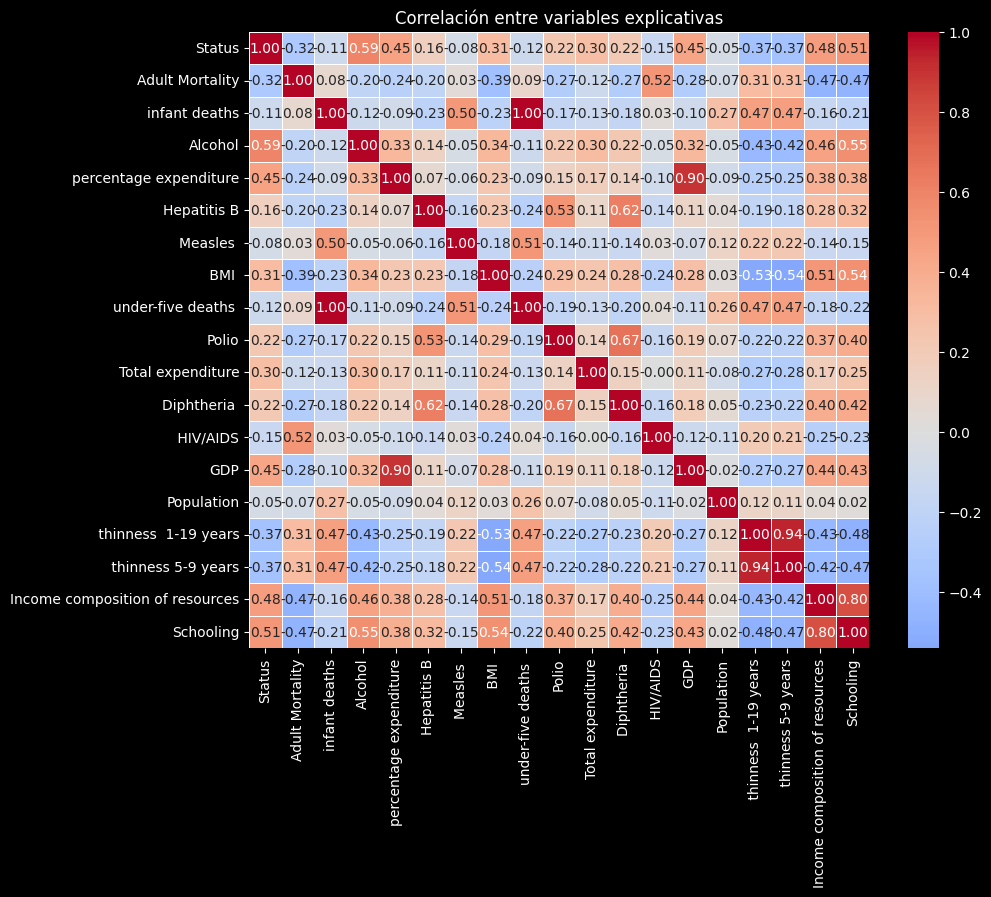

Pares con correlación > 0.8:
  infant deaths <-> under-five deaths : 1.00
  percentage expenditure <-> GDP: 0.90
   thinness  1-19 years <->  thinness 5-9 years: 0.94
  Income composition of resources <-> Schooling: 0.80


In [ ]:
# --- Multicolinealidad: correlacion ENTRE LAS EXPLICATIVAS -------------------
# Ojo con la diferencia respecto al mapa de la seccion 1.3:
#   - alli miramos correlaciones para justificar la imputacion;
#   - aqui buscamos el problema: variables que se dicen lo mismo entre si.
# Se excluye 'const' porque es una columna de unos y no tiene variacion.
corr = X.drop(columns='const').corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap='coolwarm', center=0, linewidths=.5, annot=True, fmt=".2f")
plt.title('Correlación entre variables explicativas')
plt.show()

# Se listan los pares realmente problematicos (|r| > 0.8): son los que vuelven
# inestable la inversa (X'X)^-1 y, con ella, los coeficientes de MCO.
high_corr = [(c1, c2, corr.loc[c1, c2]) for i, c1 in enumerate(corr.columns)
             for c2 in corr.columns[i+1:] if abs(corr.loc[c1, c2]) > 0.8]

print('Pares con correlación > 0.8:')
for c1, c2, v in high_corr:
    print(f'  {c1} <-> {c2}: {v:.2f}')

### 5.1 Cuantificando la multicolinealidad: el VIF

A pesar quue El mapa de calor muestra correlaciones **por pares**, pero la multicolinealidad puede repartirse entre varias variables a la vez y no verse en ningún par concreto.

El **Factor de Inflación de la Varianza (VIF)** lo mide directamente: cuánto se infla la varianza del coeficiente de una variable por su correlación con **todas** las demás.

$$VIF_j = \frac{1}{1 - R_j^2}$$

donde $R_j^2$ es el $R^2$ de regresar la variable $j$ contra el resto. Interpretación habitual: **VIF > 5** indica multicolinealidad moderada y **VIF > 10** ya es problemática.

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = X.drop(columns='const')
vif = pd.DataFrame({
    'Variable': X_vif.columns,
    'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
}).sort_values('VIF', ascending=False).reset_index(drop=True)

print('Variables con VIF > 10 (multicolinealidad problematica):',
      int((vif['VIF'] > 10).sum()), 'de', len(vif))
vif.round(2)

Variables con VIF > 10 (multicolinealidad problematica): 2 de 19


,Variable,VIF
0,under-five deaths,173.78
1,infant deaths,172.28
2,thinness 5-9 years,8.90
3,thinness 1-19 years,8.82
4,GDP,5.99
5,percentage expenditure,5.81
6,Schooling,3.64
7,Income composition of resources,3.17
8,Diphtheria,2.34
9,Polio,1.98


**¿Cómo se resolvía esto tradicionalmente?**

- Eliminando a mano una de cada par de variables correlacionadas.

**Los problemas de ese enfoque:**

- **Se pierde información:** dos variables muy correlacionadas no son idénticas, cada una aporta algo propio.
- **Es subjetivo:** ¿por qué quitar \`infant deaths\` y no \`under-five deaths\`? La decisión depende del analista.


## 6. La estrategia: regularización

Lo que se quiere es **ajustar sin excederse**: cada unidad de coeficiente ahora *cuesta*.
- $\alpha$ fija el precio.

**Por qué esto reduce la varianza:** al encarecer los coeficientes grandes, el modelo deja de perseguir el ruido de la muestra concreta.

 Acepta un poco de **sesgo** (los coeficientes quedan algo encogidos respecto al valor verdadero) a cambio de mucha menos **varianza** (cambian poco si cambian los datos).

*   trade-off sesgo-varianza




### 6.2 Ridge (penalización L2), desde cero

**La función de costo:** a la suma de residuos al cuadrado se le añade la suma de los coeficientes **al cuadrado**.

$$J_{\text{ridge}}(\beta) \;=\; \underbrace{\sum_{i=1}^{n}(y_i - X_i\beta)^2}_{\text{ajuste}} \;+\; \alpha \underbrace{\sum_{j=1}^{p} \beta_j^2}_{\text{castigo } L_2}$$

**Tiene solución exacta.** Como todo es derivable, se repite el procedimiento de MCO y se llega a:

$$\boxed{\hat{\beta}_{\text{ridge}} = (X^TX + \alpha I)^{-1}X^Ty}$$

**Compárala con la de MCO:** $\hat{\beta} = (X^TX)^{-1}X^Ty$. La única diferencia es ese $+\,\alpha I$.

> **Truco matemático completo.** $\alpha I$ suma $\alpha$ a toda la diagonal de $X^TX$. Una matriz casi singular tiene valores propios cercanos a cero, y por eso su inversa explota.

Sumar $\alpha$ los levanta a todos: la matriz **vuelve a ser invertible de forma estable**. Ridge no esquiva el problema de la multicolinealidad, lo **arregla**.



### 6.3 Lasso (penalización L1), desde cero

**La función de costo:** idéntica, pero el castigo usa el **valor absoluto** en vez del cuadrado.

$$J_{\text{lasso}}(\beta) \;=\; \sum_{i=1}^{n}(y_i - X_i\beta)^2 \;+\; \alpha \sum_{j=1}^{p} |\beta_j|$$

*(Lasso = **L**east **A**bsolute **S**hrinkage and **S**election **O**perator.)*

**No tiene solución cerrada, y la razón importa.** El valor absoluto $|\beta|$ **no es derivable en cero**: tiene un pico, una esquina. Sin derivada no se puede despejar una fórmula como la de Ridge.

- Se resuelve **numéricamente**, por lo general con *coordinate descent*: se optimiza un coeficiente a la vez dejando los demás fijos, y se repite hasta converger.
- Por eso \`Lasso()\` tiene el parámetro \`max_iter\`: es un algoritmo iterativo, no una fórmula.

**Por qué sí llega exactamente a cero.** En el mismo caso simplificado, la solución de Lasso es:

$$\hat{\beta}_j^{\,\text{lasso}} = \text{sign}(\hat{\beta}_j^{\,\text{MCO}}) \cdot \max\left(|\hat{\beta}_j^{\,\text{MCO}}| - \alpha,\; 0\right)$$

Esta operación se llama **umbral suave** (*soft thresholding*), y se lee así:

- A cada coeficiente se le **resta** $\alpha$ de su magnitud (no se le divide, se le resta).
- Si al restar queda negativo, el $\max(\cdot,\,0)$ lo deja en **cero exacto**.

> **La diferencia entera está ahí: Ridge divide, Lasso resta.** Dividir nunca llega a cero; restar sí, en cuanto $|\hat{\beta}^{\,\text{MCO}}| < \alpha$. Por eso Lasso **selecciona variables** y Ridge no.

### 6.4 La explicación geométrica

Cada problema puede escribirse de forma equivalente como *"minimiza la RSS, pero sin que los coeficientes se salgan de cierta región"*:

$$\text{Ridge}: \;\min_\beta \text{RSS} \;\text{ sujeto a }\; \sum_j \beta_j^2 \le t \qquad\qquad \text{Lasso}: \;\min_\beta \text{RSS} \;\text{ sujeto a }\; \sum_j |\beta_j| \le t$$

Con dos variables ($\beta_1$, $\beta_2$) se puede dibujar:
ridge_lasso_geometric_regions.svg

- La región permitida de **Ridge** es un **círculo** ($\beta_1^2 + \beta_2^2 \le t$): borde liso, sin esquinas.
- La región permitida de **Lasso** es un **rombo** ($|\beta_1| + |\beta_2| \le t$): tiene **cuatro esquinas, y cada esquina está justo sobre un eje**.

La solución aparece donde las curvas de nivel de la RSS **tocan por primera vez** esa región:

- Contra un **círculo**, el contacto ocurre en un punto cualquiera del borde. Que caiga exactamente sobre un eje (es decir, que un coeficiente valga cero) es prácticamente imposible.
- Contra un **rombo**, lo más probable es tocar en una **esquina**, porque sobresale. Y estar en una esquina significa **$\beta_j = 0$**.

> **En una frase:** Lasso anula coeficientes porque su región tiene picos sobre los ejes; Ridge no lo hace porque la suya es redonda.

### 6.5 ¿Cómo se elige $\alpha$?

$\alpha$ no se estima con los datos como los $\beta$: es un **hiperparámetro**, se elige probando.

**Validación cruzada de $k$ pliegues (aquí $k=5$):**

1. Se parten los datos de entrenamiento en 5 bloques.
2. Para cada valor candidato de $\alpha$: se entrena con 4 bloques y se evalúa en el que quedó fuera.
3. Se rota, de modo que cada bloque sirva una vez de evaluación.
4. Se promedian los 5 resultados.
5. Gana el $\alpha$ con mejor promedio.

**Por qué así y no eligiendo el $\alpha$ que mejor ajuste los datos de entrenamiento:** ese siempre sería $\alpha = 0$, es decir, MCO. El mejor ajuste sobre datos ya vistos nunca premia la prudencia; hay que medir sobre datos apartados.

\`GridSearchCV\` automatiza exactamente este procedimiento.

## 7. Aplicación: Regresión Ridge

In [ ]:
# --- Ridge: busqueda del mejor alpha por validacion cruzada ------------------
# Se prueban 5 valores de alpha separados por factores de 100, y para cada uno
# se hace validacion cruzada de 5 pliegues (seccion 6.5). Gana el de mejor R2.
ridge_search = GridSearchCV(Ridge(), {'alpha': [1e-4, 1e-2, 1, 1e2, 1e4]}, scoring='r2', cv=5)
ridge_search.fit(X, y)
print('Mejor alpha (Ridge):', ridge_search.best_params_)

# best_estimator_ ya viene con el mejor alpha; se reajusta sobre todos los datos.
ridge = ridge_search.best_estimator_
ridge.fit(X, y)
y_pred_ridge = ridge.predict(X)

print('R2  :', r2_score(y, y_pred_ridge))
print('MSE :', mean_squared_error(y, y_pred_ridge))

Mejor alpha (Ridge): {'alpha': 1}
R2  : 0.8357293871789814
MSE : 14.844223907853586


En Regresión Ridge se esta aplicando búsqueda en grilla **(GridSearchCV)** y validación cruzada para la optimización de hiperparámetros.Se definió un rango amplio para el parámetro de regularización ($\alpha \in \{10^{-4}, 10^{-2}, 1, 10^{2}, 10^{4}\}$) con el fin de evaluar desde penalizaciones casi nulas hasta penalizaciones severas. Para la validación cruzada ($k=5$):Los datos se dividieron en 5 pliegues (folds). En cada iteración, el modelo se entrenó con el 80% de los datos y se evaluó con el 20% restante utilizando el coeficiente de determinación ($R^2$) como métrica de selección.

**Para el re-entranamiento**: Tras identificar el $\alpha$ que maximizó el $R^2$ promedio en validación, se seleccionó dicho modelo (best_estimator_) y se re-entrenó sobre la totalidad del dataset ($X, y$) para generar las predicciones finales.

**Mejor Alpha**: El valor de obtención de un $\alpha$ = 1, que aplica una penalización moderada los coeficientes. Es lo suficientemente fuerte como para controlar la alta multicolinealidad entre covariables pero sin contraer los parámetros al punto de perder la capacidad explicativa.

**($R^2$)**: El modelo presenta una alta capcidad explicativa, explicando aproximadamente el 83.6% de la varianza de la esperanza de vida.

**MSE**: Mide el promedio de errores al cuadrado y el valor 14.84, el modelo no presenta errores extremos atípicos significativos.

## 8. Aplicación: Regresión Lasso

In [ ]:
# --- Lasso: mismo procedimiento, distinta penalizacion -----------------------
# Misma rejilla de alpha que Ridge, para que la comparacion sea justa.
lasso_search = GridSearchCV(Lasso(), {'alpha': [1e-4, 1e-2, 1, 1e2, 1e4]}, scoring='r2', cv=5)
lasso_search.fit(X, y)
print('Mejor alpha (Lasso):', lasso_search.best_params_)

lasso = lasso_search.best_estimator_
lasso.fit(X, y)
y_pred_lasso = lasso.predict(X)

print('R2  :', r2_score(y, y_pred_lasso))
print('MSE :', mean_squared_error(y, y_pred_lasso))

# La linea que distingue a Lasso de Ridge: contar cuantos coeficientes quedaron
# EXACTAMENTE en cero. En Ridge este numero seria siempre 0 (seccion 6.2).
print('Coeficientes llevados a 0 por Lasso:', (lasso.coef_ == 0).sum(), 'de', len(lasso.coef_))

Mejor alpha (Lasso): {'alpha': 0.01}
R2  : 0.8350566082761113
MSE : 14.905019204730973
Coeficientes llevados a 0 por Lasso: 2 de 20


El código ejecuta una estrategia de selección y estimación regularizada mediante Regresión Lasso (Least Absolute Shrinkage and Selection Operator), manteniendo la misma grilla de hiperparámetros que en Ridge ($\alpha \in \{10^{-4}, 10^{-2}, 1, 10^{2}, 10^{4}\}$) y validación cruzada de 5 pliegues ($k=5$).La diferencia fundamental radica en que Lasso utiliza una penalización $L_1$, la cual no solo encoge los coeficientes, sino que realiza selección automática de variables al forzar a que algunos coeficientes sean exactamente cero.

**Mejor $\alpha$**: Para Lasso $\alpha$ = 0.01  es suficiente para regularizar el modelo; Lasso suele requerir valores más pequeños debido al nivel de penalización.

**($R^2$)**: El modelo presenta una alta capcidad explicativa, explicando aproximadamente el 83.5% de la varianza de la esperanza de vida.

**MSE**: Mide el promedio de errores al cuadrado y el valor 14.91, el modelo no presenta errores extremos atípicos significativos.

Lasso eliminó 2 variables redundantes por completo

## 9. Comparación de coeficientes: MCO vs Ridge vs Lasso

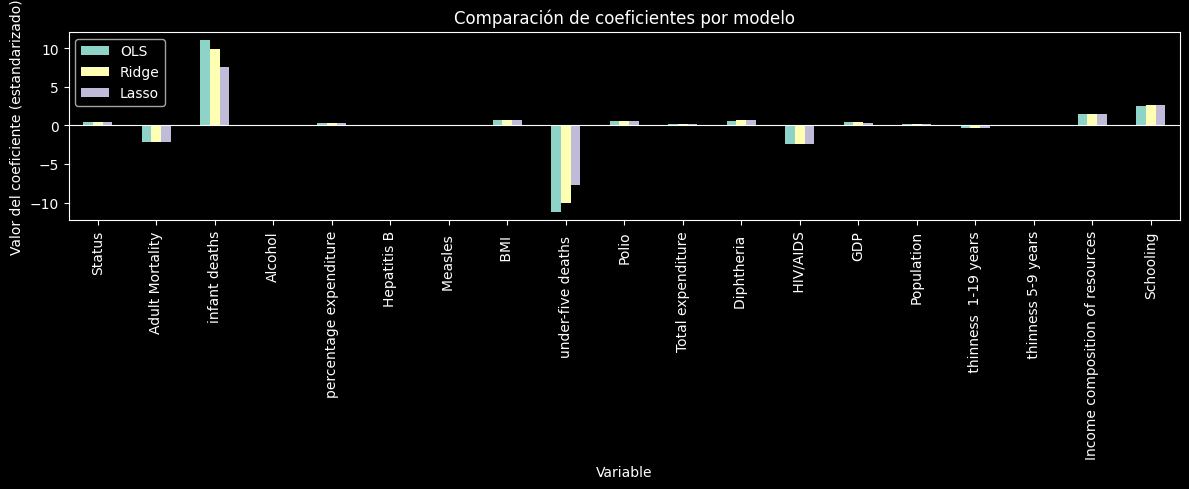

In [ ]:
# --- Comparacion visual de los tres vectores de coeficientes -----------------
# Misma variable, tres barras: cuanto peso le da cada modelo.
coef_df = pd.DataFrame({
    'Variable': X.columns,
    'OLS'     : ols.params.values,
    'Ridge'   : ridge.coef_,
    'Lasso'   : lasso.coef_
}).set_index('Variable').drop('const')   # 'const' fuera: es el intercepto, no una variable

coef_df.plot(kind='bar', figsize=(12, 5), title='Comparación de coeficientes por modelo')
plt.axhline(0, color='white', linewidth=0.8)   # referencia: la linea del cero
plt.ylabel('Valor del coeficiente (estandarizado)')
plt.tight_layout()
plt.show()



- **Ridge encoge** los coeficientes respecto a MCO, y lo hace con más fuerza en las **variables correlacionadas entre sí**.
- **Lasso lleva varios coeficientes exactamente a cero**, quedándose con el subconjunto de variables más relevante.
- Las barras de MCO son las **más extremas**: es el modelo sin ninguna restricción sobre el tamaño de sus coeficientes.



### 9.1 Términos cuadráticos: ¿y si el efecto no es una recta?

Hasta acá, MCO, Ridge y Lasso solo pudieron capturar relaciones **lineales**: una recta entre cada variable y `Life expectancy `. Si el efecto real es curvo (por ejemplo, que `BMI` o `Adult Mortality` tengan un punto óptimo, o un efecto que se acelera), el modelo lineal no lo ve, sin importar cuánta regularización se le aplique.

**Solución simple: agregar el cuadrado de cada variable numérica** como columna nueva (`variable_2`). El modelo sigue siendo lineal *en los coeficientes*, pero ahora puede ajustar curvas: `y = ... + b1*x + b2*x^2 + ...`

Se excluyen de este paso:
- `Status`: es binaria (0/1), elevarla al cuadrado no cambia nada (`0^2=0`, `1^2=1`).
- `Life expectancy `, `Country`, `Year`: no son variables explicativas (ver 1.2 y 3).

**Por qué justo acá:** en las secciones 4 a 9 ya viste cómo Ridge y Lasso actúan sobre las 19 variables originales. La pregunta ahora es otra: si le doy al modelo el doble de variables, cada una fuertemente correlacionada con su propio cuadrado por construcción, **¿Ridge y Lasso siguen siendo útiles, y de qué forma distinta?**


In [ ]:
# --- Variables al cuadrado (ver seccion 9.1) ----------------------------------
# Se trabaja sobre una copia de 'data' para no perder el dataset simple
# que ya se uso en las secciones 3-9.
data_amp = data.copy()

excluir = ['Life expectancy ', 'Country', 'Year', 'Status']
cols_cuadrado = [c for c in data_amp.select_dtypes(include=[np.number]).columns if c not in excluir]

for c in cols_cuadrado:
    data_amp[c + '_2'] = data_amp[c] ** 2

print('Variables elevadas al cuadrado:', len(cols_cuadrado))
print('Columnas nuevas:', [c + '_2' for c in cols_cuadrado])
print('Dimensiones de data_amp:', data_amp.shape)


Variables elevadas al cuadrado: 18
Columnas nuevas: ['Adult Mortality_2', 'infant deaths_2', 'Alcohol_2', 'percentage expenditure_2', 'Hepatitis B_2', 'Measles _2', ' BMI _2', 'under-five deaths _2', 'Polio_2', 'Total expenditure_2', 'Diphtheria _2', ' HIV/AIDS_2', 'GDP_2', 'Population_2', ' thinness  1-19 years_2', ' thinness 5-9 years_2', 'Income composition of resources_2', 'Schooling_2']
Dimensiones de data_amp: (2938, 40)


### 9.2 Re-preparación de $X$ y re-escalado

Se repite el procedimiento de la sección 3, ahora sobre `data_amp`. Se guarda también la versión **sin escalar** (`X_amp_raw`): se necesita en la sección 12 para ajustar el `StandardScaler` solo con datos de entrenamiento y evitar la fuga de datos que se cuela si se escala antes de dividir train/test.


In [ ]:
# --- Re-separacion y re-escalado, ahora con las columnas cuadraticas --------
X_amp_raw = data_amp.drop(['Life expectancy ', 'Country', 'Year'], axis=1)   # sin escalar, sin const

cols_amp = X_amp_raw.columns
X_amp = pd.DataFrame(StandardScaler().fit_transform(X_amp_raw), columns=cols_amp)
X_amp = sm.add_constant(X_amp)

print('Variables simples (seccion 3)   :', X.shape[1] - 1)
print('Variables ampliadas (seccion 9) :', X_amp.shape[1] - 1)
X_amp.head()


Variables simples (seccion 3)   : 19
Variables ampliadas (seccion 9) : 37


,const,Status,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,...,Polio_2,Total expenditure_2,Diphtheria _2,HIV/AIDS_2,GDP_2,Population_2,thinness 1-19 years_2,thinness 5-9 years_2,Income composition of resources_2,Schooling_2
0,1.0,-0.459399,0.791586,0.268824,-1.162377,-0.335570,-0.587067,-0.110384,-0.95681,0.255359,...,-2.632201,0.754289,-1.111683,-0.167116,-0.247983,-0.165695,3.046196,2.919910,-0.918935,-0.686648
1,1.0,-0.459399,0.856072,0.285786,-1.162377,-0.334441,-0.709594,-0.168124,-0.98186,0.274060,...,-1.437026,0.763964,-1.247575,-0.167116,-0.247945,-0.184801,3.171651,2.999563,-0.931816,-0.713259
2,1.0,-0.459399,0.831890,0.302749,-1.162377,-0.334594,-0.627909,-0.173531,-1.00691,0.292761,...,-1.264645,0.739821,-1.157694,-0.167116,-0.247918,-0.167899,3.256493,3.080131,-0.957334,-0.739604
3,1.0,-0.459399,0.864132,0.328193,-1.162377,-0.332096,-0.505382,0.032045,-1.03196,0.317696,...,-1.033008,0.932066,-1.017522,-0.167116,-0.247862,-0.184574,3.342299,3.202700,-0.986695,-0.765685
4,1.0,-0.459399,0.888314,0.345155,-1.162377,-0.367862,-0.464539,0.051757,-1.05200,0.342631,...,-0.984526,0.616661,-0.969372,-0.167116,-0.248364,-0.184654,3.472816,3.285557,-1.023799,-0.842339


### 9.3 Ridge y Lasso con variables ampliadas

Mismo procedimiento de las secciones 4, 7 y 8: se ajusta MCO como referencia y se busca el mejor $\alpha$ de Ridge y Lasso por validación cruzada, ahora sobre `X_amp` (37 variables en vez de 19).


In [ ]:
# --- OLS, Ridge y Lasso sobre X_amp -------------------------------------------
ols_amp = sm.OLS(y, X_amp).fit()
y_pred_ols_amp = ols_amp.predict(X_amp)

ridge_amp_search = GridSearchCV(Ridge(), {'alpha': [1e-4, 1e-2, 1, 1e2, 1e4]}, scoring='r2', cv=5)
ridge_amp_search.fit(X_amp, y)
ridge_amp = ridge_amp_search.best_estimator_
ridge_amp.fit(X_amp, y)
y_pred_ridge_amp = ridge_amp.predict(X_amp)

lasso_amp_search = GridSearchCV(Lasso(max_iter=10000), {'alpha': [1e-4, 1e-2, 1, 1e2, 1e4]}, scoring='r2', cv=5)
lasso_amp_search.fit(X_amp, y)
lasso_amp = lasso_amp_search.best_estimator_
lasso_amp.fit(X_amp, y)
y_pred_lasso_amp = lasso_amp.predict(X_amp)

print('Mejor alpha Ridge (ampliado):', ridge_amp_search.best_params_)
print('Mejor alpha Lasso (ampliado):', lasso_amp_search.best_params_)
print('R2 OLS / Ridge / Lasso (ampliado):',
      round(r2_score(y, y_pred_ols_amp), 4),
      round(r2_score(y, y_pred_ridge_amp), 4),
      round(r2_score(y, y_pred_lasso_amp), 4))

cuadraticos = [c for c in X_amp.columns if c.endswith('_2')]
coef_lasso_amp = pd.Series(lasso_amp.coef_, index=X_amp.columns)
print('Terminos cuadraticos totales      :', len(cuadraticos))
print('Terminos cuadraticos en 0 (Lasso) :', int((coef_lasso_amp[cuadraticos] == 0).sum()))


Mejor alpha Ridge (ampliado): {'alpha': 100.0}
Mejor alpha Lasso (ampliado): {'alpha': 1}
R2 OLS / Ridge / Lasso (ampliado): 0.8861 0.8705 0.8231
Terminos cuadraticos totales      : 18
Terminos cuadraticos en 0 (Lasso) : 12


### 9.4 Comparación de coeficientes: simple vs. ampliado


In [ ]:
resumen_amp = pd.DataFrame({
    'Modelo': ['OLS simple', 'Ridge simple', 'Lasso simple',
               'OLS ampliado', 'Ridge ampliado', 'Lasso ampliado'],
    'Variables': [X.shape[1]-1]*3 + [X_amp.shape[1]-1]*3,
    'Activas (coef != 0)': [
        int((ols.params.drop('const') != 0).sum()),
        int((ridge.coef_ != 0).sum()),
        int((lasso.coef_ != 0).sum()),
        int((ols_amp.params.drop('const') != 0).sum()),
        int((ridge_amp.coef_ != 0).sum()),
        int((lasso_amp.coef_ != 0).sum()),
    ]
})
resumen_amp


,Modelo,Variables,Activas (coef != 0)
0,OLS simple,19,19
1,Ridge simple,19,19
2,Lasso simple,19,18
3,OLS ampliado,37,37
4,Ridge ampliado,37,37
5,Lasso ampliado,37,7


- **OLS ampliado** usa las 37 variables completas: no puede apagar nada, y con `x` y `x²` tan correlacionadas entre sí, sus coeficientes son aún más inestables que en la sección 4.
- **Ridge ampliado** reparte el peso entre cada variable y su cuadrado, pero mantiene las 37 activas.
- **Lasso ampliado** es el único que **decide** qué curvaturas aportan de verdad y apaga el resto — esa es su ventaja frente a solo agregar más columnas y regularizar con Ridge.

De acá en adelante (residuales, comparación final, validación honesta, camino de regularización y conclusiones) se trabaja con el modelo **ampliado**, porque es el que incorpora todo lo aprendido hasta este punto.


## 10. Análisis de residuales

In [ ]:
# --- Analisis de residuales --------------------------------------------------
# Residuo = valor real - valor predicho. Se grafica contra el valor real.
# Que buscamos: una nube SIN patron alrededor del cero. Si aparece forma de
# embudo o curva, el modelo lineal se esta dejando estructura sin explicar.
fig = make_subplots(rows=1, cols=3, subplot_titles=('MCO', 'Ridge', 'Lasso'))

for i, (name, pred) in enumerate([('MCO', y_pred_ols), ('Ridge', y_pred_ridge), ('Lasso', y_pred_lasso)]):
    resid = np.array(y) - np.array(pred)
    fig.add_trace(go.Scatter(x=y, y=resid, mode='markers', opacity=0.5, name=name), row=1, col=i + 1)
    fig.add_hline(y=0, row=1, col=i + 1)   # el cero: donde el modelo acierta

fig.update_layout(height=400, showlegend=False, title_text='Residuales vs. valor real (Life expectancy)')
fig.show()

Las graficas de **Residuales vs. valor real** muestra heterocedasticidad (patrón en forma de embudo), al igual que sobreestimación en los tres modelos, asignando valores mayores que los reales. Las predicciones a esperanzas de vida altas es mayor a valores menores. La dispersión del error aumenta. Las nubes de puntos de los tres algoritmos son similares/identicas lo que demuestra que la regularización reduce la inestabilidad por multicolinealidad, pero no corrige por sí sola las relaciones no lineales del dataset sin el uso de terminos cuadráticos o transformaciones.

## 11. Conclusión: comparación final de métricas

In [ ]:
# --- Metricas "no honestas": evaluadas sobre los mismos datos de entrenamiento ---
# (la validacion HONESTA, con train/test, se calcula en la seccion 12)
validacion_rapida = pd.DataFrame({
    'Modelo': ['OLS ampliado', 'Ridge ampliado', 'Lasso ampliado'],
    'R2': [
        r2_score(y, y_pred_ols_amp),
        r2_score(y, y_pred_ridge_amp),
        r2_score(y, y_pred_lasso_amp),
    ],
    'MSE': [
        mean_squared_error(y, y_pred_ols_amp),
        mean_squared_error(y, y_pred_ridge_amp),
        mean_squared_error(y, y_pred_lasso_amp),
    ]
}).set_index('Modelo').round(4)

display(validacion_rapida)


,R2,MSE
Modelo,,
OLS ampliado,0.8861,10.2958
Ridge ampliado,0.8705,11.7047
Lasso ampliado,0.8231,15.9869


**Comparación de los tres modelos:**

- Los tres alcanzan un **ajuste ($R^2$ y MSE) prácticamente idéntico**.
- **Ridge** logra ese mismo ajuste con coeficientes **más estables y mejor repartidos** entre variables correlacionadas.
- **Lasso** consigue un modelo **más simple**, con menos variables activas.

Pero ;
 las tres métricas están calculadas sobre **los mismos datos con los que se entrenaron los modelos**. Medido así, MCO no puede perder.

**Por eso la comparación no termina aquí.**

---

## 12. Validación honesta: ¿de verdad generalizan mejor?

Como aquí entrenamos y evaluamos sobre **los mismos datos** Ridge y Lasso añaden una penalización, así que ahí sólo pueden ajustar igual o peor.


De paso corregimos dos detalles técnicos:

1. **El intercepto no debe penalizarse.**
2. **Grilla de $\alpha$ más fina.** La grilla original \`[1e-4, 1e-2, 1, 1e2, 1e4]\` salta de a ×100, y Ridge eligió \`alpha=1\`, justo el valor central: no podía distinguir entre 0.3 y 3. Usamos \`np.logspace(-4, 4, 50)\`.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Se quita 'const': sklearn ya ajusta el intercepto y no debe regularizarlo.
X_sk = X.drop(columns='const')

X_train, X_test, y_train, y_test = train_test_split(
    X_sk, y, test_size=0.3, random_state=42
)

print('Entrenamiento:', X_train.shape)
print('Prueba       :', X_test.shape)

Entrenamiento: (2056, 19)
Prueba       : (882, 19)


In [ ]:
alphas = np.logspace(-4, 4, 50)

lin_v      = LinearRegression().fit(X_train, y_train)
ridge_v_cv = GridSearchCV(Ridge(), {'alpha': alphas}, scoring='r2', cv=5).fit(X_train, y_train)
lasso_v_cv = GridSearchCV(Lasso(max_iter=10000), {'alpha': alphas}, scoring='r2', cv=5).fit(X_train, y_train)

ridge_v = ridge_v_cv.best_estimator_
lasso_v = lasso_v_cv.best_estimator_

print('Mejor alpha Ridge:', round(ridge_v_cv.best_params_['alpha'], 5))
print('Mejor alpha Lasso:', round(lasso_v_cv.best_params_['alpha'], 5))

filas = []
for nombre, m in [('MCO (OLS)', lin_v), ('Ridge', ridge_v), ('Lasso', lasso_v)]:
    filas.append({
        'Modelo'     : nombre,
        'R2 train'   : r2_score(y_train, m.predict(X_train)),
        'R2 test'    : r2_score(y_test,  m.predict(X_test)),
        'MSE test'   : mean_squared_error(y_test, m.predict(X_test)),
        'Coef. != 0' : int((m.coef_ != 0).sum())
    })

validacion = pd.DataFrame(filas).set_index('Modelo').round(4)
validacion

Mejor alpha Ridge: 0.39069
Mejor alpha Lasso: 0.00202


,R2 train,R2 test,MSE test,Coef. != 0
Modelo,,,,
MCO (OLS),0.8335,0.838,15.1385,19
Ridge,0.8335,0.838,15.1384,19
Lasso,0.8335,0.838,15.1400,19


Inicialmente los datos presentaban un problema de multicolinealidad e incorporacion de variables no lineales como lineales. Al evaluarlos en datos nuevos, los tres modelos explicaron el 83.8% de los casos y se equivocaron por unos 3.8 años en promedio. No obstante, al agregar 18 variables al cuadrado (pasando a 37 variables) en este caso MCO empezo a ajustarse a los datos iniciales (sobreajuste de colinealidad estructural), Lasso elimino curvas utiles y Ridge elimino las curvas necesarias. **Para el dataset con 19 variables la regularización no genera una mejora significativa frente a MCO**

## 13. El camino de regularización

Este es **el** gráfico que hace visible la diferencia entre las dos penalizaciones. En el eje horizontal crece $\alpha$; cada línea es un coeficiente.

- En **Ridge (L2)** las curvas se acercan a cero de forma suave y asintótica: se encogen todas juntas, pero ninguna llega a tocar el cero.
- En **Lasso (L1)** las curvas **tocan el cero y se quedan ahí**, una por una, a medida que $\alpha$ crece. Eso es la selección automática de variables.

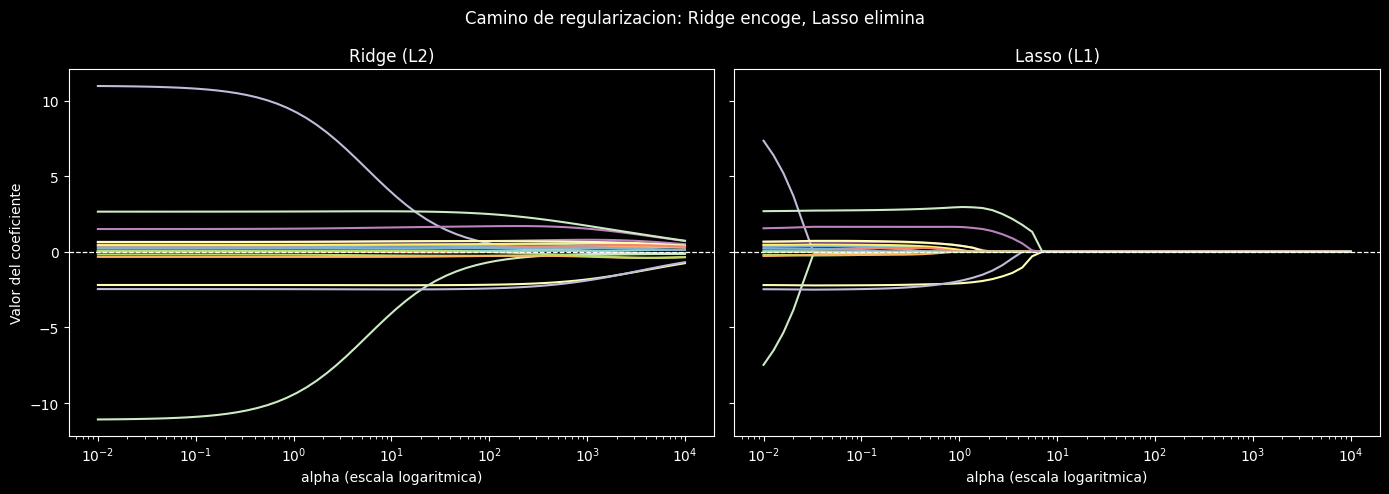

In [ ]:
alphas_path = np.logspace(-2, 4, 60)
coefs_ridge, coefs_lasso = [], []

for a in alphas_path:
    coefs_ridge.append(Ridge(alpha=a).fit(X_train, y_train).coef_)
    coefs_lasso.append(Lasso(alpha=a, max_iter=10000).fit(X_train, y_train).coef_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, coefs, titulo in zip(axes, [coefs_ridge, coefs_lasso], ['Ridge (L2)', 'Lasso (L1)']):
    ax.plot(alphas_path, coefs)
    ax.set_xscale('log')
    ax.axhline(0, color='white', lw=0.9, ls='--')
    ax.set_xlabel('alpha (escala logaritmica)')
    ax.set_title(titulo)

axes[0].set_ylabel('Valor del coeficiente')
plt.suptitle('Camino de regularizacion: Ridge encoge, Lasso elimina')
plt.tight_layout()
plt.show()

#seleccionar/utilizar un lamda

Este gráfico muestra la diferencia técnica  entre ambos métodos: Ridge encoge y Lasso elimina. Mientras que la penalización $L_2$ de Ridge comprime los coeficientes hacia el cero a medida que aumenta $\alpha$ sin descartar nunca ningún predictor (los 19 siguen activos), la penalización $L_1$ de Lasso actúa como una guillotina que fuerza a las variables a valer cero exacto una a una conforme crece el castigo. Además, se observa claramente por qué en el paso 12 ambos modelos mantuvieron las 19 variables: la validación cruzada seleccionó un $\alpha$ tan pequeño ($0.00202$) que se ubica en el extremo izquierdo del gráfico, donde Lasso aún no ha comenzado a anular ninguna variable.

In [ ]:
# --- ¿Que nos dice el modelo sobre la esperanza de vida? ---------------------
# Los coeficientes estan en unidades estandarizadas, asi que SI son comparables
# entre si: cada uno indica cuantos anios de esperanza de vida se asocian a un
# aumento de una desviacion estandar en esa variable, con lo demas constante.

importancia = pd.DataFrame({
    'Variable'    : X_sk.columns,
    'Coeficiente' : ridge_v.coef_
})
importancia['Magnitud'] = importancia['Coeficiente'].abs()
importancia['Efecto']   = np.where(importancia['Coeficiente'] > 0, 'SUBE la esperanza', 'la BAJA')

importancia = importancia.sort_values('Magnitud', ascending=False).reset_index(drop=True)

print('Error tipico del modelo (RMSE):', round(mean_squared_error(y_test, ridge_v.predict(X_test)) ** 0.5, 2), 'anios')
print()
print('Factores ordenados por influencia (modelo Ridge):')
importancia.round(3)

Error tipico del modelo (RMSE): 3.89 anios

Factores ordenados por influencia (modelo Ridge):


,Variable,Coeficiente,Magnitud,Efecto
0,under-five deaths,-10.384,10.384,la BAJA
1,infant deaths,10.261,10.261,SUBE la esperanza
2,Schooling,2.658,2.658,SUBE la esperanza
3,HIV/AIDS,-2.466,2.466,la BAJA
4,Adult Mortality,-2.195,2.195,la BAJA
5,Income composition of resources,1.515,1.515,SUBE la esperanza
6,BMI,0.661,0.661,SUBE la esperanza
7,Diphtheria,0.649,0.649,SUBE la esperanza
8,Status,0.473,0.473,SUBE la esperanza
9,Polio,0.445,0.445,SUBE la esperanza


## 14. Conclusiónes

**1. No hay sobreajuste que corregir.** El $R^2$ de entrenamiento (0.8335) es incluso *menor* que el de prueba (0.8380).

**2. Sobran datos por parámetro.** El dataset tiene $n = 2938$ observaciones y $p = 19$ variables: unos **155 datos por coeficiente**. MCO ya estima con varianza baja.

### Entonces, ¿la multicolinealidad no importaba?

Sí importa, pero afecta a otra cosa. El VIF de la sección 5.1 confirmó multicolinealidad **severa**: \`under-five deaths\` (173.8) e \`infant deaths\` (172.3) son prácticamente la misma variable medida dos veces.

!!! Por eso el aporte real de Ridge y Lasso en este trabajo es de **interpretabilidad y estabilidad**, no de precisión: reparten el peso entre las variables correlacionadas en lugar de asignarlo de forma arbitraria a una sola.

## 15. En términos de los datos

- Modelo Explica alrededor del **84 % de la variación** en la esperanza de vida entre países y años ($R^2 = 0.838$ sobre datos no vistos).
- Se equivoca, en promedio, en unos **3.9 años** (RMSE) sobre un rango que va de 36 a 89 años.
- Es un ajuste **bueno para datos sociales**, donde la variabilidad entre países es enorme.
- El **16 % restante** queda sin explicar: conflictos armados, calidad institucional, geografía, cultura — cosas que este conjunto de variables no mide.

